In [1]:
import datajoint as dj
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from multimodal_analysis.db import get_schema_modules

exp, stim, beh, inter, rec, mice = get_schema_modules()

from multimodal_analysis.config import (
    add_behavior_sessions,
    create_analysis_key,
    get_animal_ids,
    get_behavior_sessions,
    get_task_types,
    plot_behavior_task_types,
    remove_behavior_sessions,
)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-11-06 21:15:32,535][INFO]: Connecting eflab@database.eflab.org:3306
[2026-11-06 21:15:32,566][INFO]: Connected eflab@database.eflab.org:3306


In [42]:
animals = get_animal_ids()
# animals = [299]
animals

['288', '299', '324', '326', '328', '410']

In [70]:
performance_sessions = []
# obj_ids = {212, 213, 217, 218}

for animal in animals:
    task_type = "visual"
    
    excluded_sessions = []

    # Get the behavioral sessions available for the selected animal and task.
    sessions_idx = get_behavior_sessions(animal_id=animal, task_type=task_type)

    # Exclude sessions if necessary.
    sessions_idx = [
        session for session in sessions_idx if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # unimodal-visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & key
                # & 'obj_id IN (212,213,217,218)'
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # unimodal-auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                # & 'obj_id IN (212,213,217,218)'
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

        # multimodal trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                # & 'obj_id IN (212,213,217,218)'
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()

        # Count valid trials in each modality.
        n_visual = len(vis_trials)
        n_auditory = len(auditory_trials)
        n_audiovisual = len(multi_trials)

        print(
            f"Animal {animal}, Session {session}: "
            f"Visual={n_visual}, "
            f"Auditory={n_auditory}, "
            f"Audiovisual={n_audiovisual}"
        )

        # Apply session inclusion criteria.
        # 1. At least 100 audiovisual trials.
        # 2. At least 50 unimodal trials in total (visual + auditory).
        # 3. All three modalities must be present.
        # if (
        #     n_audiovisual < 100
        #     or (n_visual + n_auditory) < 50
        #     or n_visual == 0
        #     or n_auditory == 0
        # ):
        #     continue

        # Calculate performance for each modality.
        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_trials, "Audiovisual"),
        ]:
            df = df.copy()
            df["modality"] = modality
            performance_sessions.append(df)

# Combine all trials.
performance_df = pd.concat(performance_sessions, ignore_index=True)

# Calculate the number of rewarded and punished trials.
performance_by_session = (
    performance_df
    .groupby(["animal_id", "session", "modality", "state"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure both outcome columns exist, even if a group has no trials of one type.
for state in ["Reward", "Punish"]:
    if state not in performance_by_session.columns:
        performance_by_session[state] = 0

# Calculate valid trials and performance.
performance_by_session["n_trials"] = (
    performance_by_session["Reward"]
    + performance_by_session["Punish"]
)

performance_by_session["performance"] = (
    performance_by_session["Reward"]
    / performance_by_session["n_trials"]
)

performance_by_session["performance_pct"] = (
    performance_by_session["performance"] * 100
)

Animal 288, Session 144: Visual=333, Auditory=0, Audiovisual=0
Animal 288, Session 146: Visual=245, Auditory=0, Audiovisual=0
Animal 288, Session 149: Visual=327, Auditory=0, Audiovisual=0
Animal 288, Session 153: Visual=310, Auditory=0, Audiovisual=0
Animal 288, Session 155: Visual=146, Auditory=0, Audiovisual=0
Animal 288, Session 157: Visual=326, Auditory=0, Audiovisual=0
Animal 288, Session 159: Visual=383, Auditory=0, Audiovisual=0
Animal 288, Session 161: Visual=342, Auditory=0, Audiovisual=0
Animal 288, Session 163: Visual=326, Auditory=0, Audiovisual=0
Animal 288, Session 165: Visual=323, Auditory=0, Audiovisual=0
Animal 288, Session 170: Visual=347, Auditory=0, Audiovisual=0
Animal 288, Session 172: Visual=351, Auditory=0, Audiovisual=0
Animal 288, Session 174: Visual=322, Auditory=0, Audiovisual=0
Animal 288, Session 176: Visual=285, Auditory=0, Audiovisual=0
Animal 288, Session 178: Visual=292, Auditory=0, Audiovisual=0
Animal 288, Session 180: Visual=304, Auditory=0, Audiov

In [71]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

performance_by_session 

state,animal_id,session,modality,Punish,Reward,n_trials,performance,performance_pct
0,288,144,Visual,133,200,333,0.600601,60.060060
1,288,146,Visual,96,149,245,0.608163,60.816327
2,288,149,Visual,127,200,327,0.611621,61.162080
3,288,153,Visual,110,200,310,0.645161,64.516129
4,288,155,Visual,54,92,146,0.630137,63.013699
5,288,157,Visual,126,200,326,0.613497,61.349693
6,288,159,Visual,183,200,383,0.522193,52.219321
7,288,161,Visual,142,200,342,0.584795,58.479532
8,288,163,Visual,126,200,326,0.613497,61.349693
9,288,165,Visual,123,200,323,0.619195,61.919505


In [79]:
print(np.unique(performance_by_session["animal_id"]))

print(
    "Total unique sessions:",
    performance_by_session[["animal_id", "session"]].drop_duplicates().shape[0],
)

for animal, df in performance_by_session.groupby("animal_id"):
    n_sessions = df["session"].nunique()
    print(f"Animal {animal}: {n_sessions} sessions")

[288 299 324 326 328 410]
Total unique sessions: 123
Animal 288: 33 sessions
Animal 299: 10 sessions
Animal 324: 20 sessions
Animal 326: 16 sessions
Animal 328: 26 sessions
Animal 410: 18 sessions


In [80]:
performance_by_session["session_position"] = (
    performance_by_session
    .groupby("animal_id")["session"]
    .rank(method="dense")
)

performance_across_animals = (
    performance_by_session
    .groupby(["session_position", "modality"])["performance_pct"]
    .agg(
        mean_performance="mean",
        sd_performance="std",
        n_animals="count",
    )
    .reset_index()
)
performance_across_animals

,session_position,modality,mean_performance,sd_performance,n_animals
0,1.0,Visual,41.520183,22.230112,6
1,2.0,Visual,43.016844,18.454546,6
2,3.0,Visual,43.347187,19.992697,6
3,4.0,Visual,50.313127,16.887577,6
4,5.0,Visual,47.870503,19.406712,6
5,6.0,Visual,48.006073,15.090055,6
6,7.0,Visual,49.064386,13.125819,6
7,8.0,Visual,53.364104,13.875251,6
8,9.0,Visual,51.147114,11.850138,6
9,10.0,Visual,54.186551,14.125563,6


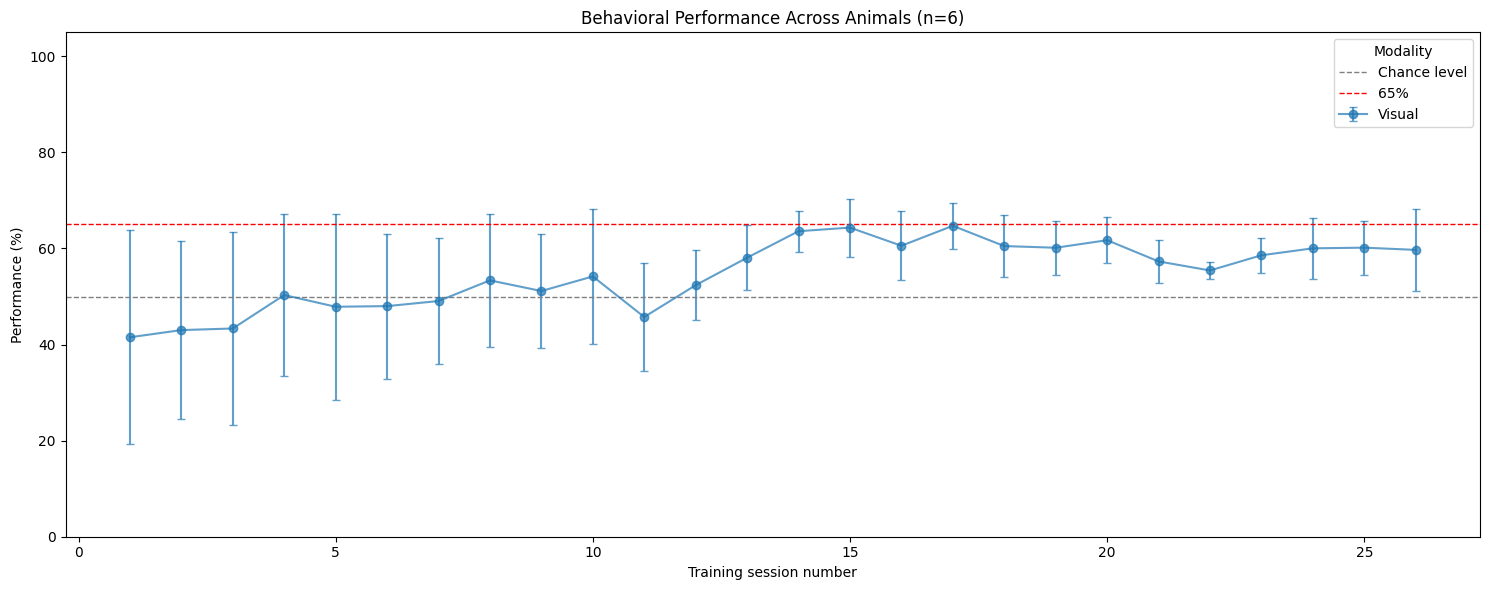

In [82]:
plt.figure(figsize=(15, 6))

# plot_df = performance_across_animals[
#     performance_across_animals["n_animals"] >= 2
# ].copy()

# display(plot_df)

for modality, data in plot_df.groupby("modality"):
    data = data.sort_values("session_position")

    plt.errorbar(
        data["session_position"],
        data["mean_performance"],
        yerr=data["sd_performance"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        label=modality,
        alpha=0.7,
    )

plt.axhline(
    y=50,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Chance level",
)

plt.axhline(
    y=65,
    color="red",
    linestyle="--",
    linewidth=1,
    label="65%",
)


plt.xlabel("Training session number")
plt.ylabel("Performance (%)")
plt.title(
    f"Behavioral Performance Across Animals "
    f"(n={performance_by_session['animal_id'].nunique()})"
)
plt.ylim(0, 105)
plt.legend(title="Modality")
plt.tight_layout()
plt.show()

Plot the number of animals across sessions

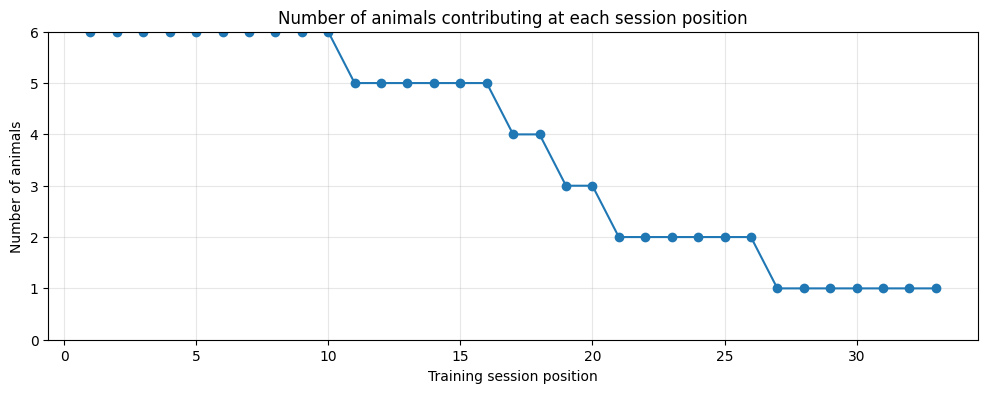

In [83]:
(
    performance_across_animals
    .groupby("session_position")["n_animals"]
    .first()
    .plot(
        marker="o",
        figsize=(12, 4),
    )
)

plt.xlabel("Training session position")
plt.ylabel("Number of animals")
plt.title("Number of animals contributing at each session position")
plt.ylim(0, 6)
plt.grid(alpha=0.3)
plt.show()

In [60]:
# per animal mean performance across sessions
# per modality
performance_by_animal = (
    performance_by_session
    .groupby(["animal_id", "modality"])["performance_pct"]
    .mean()
    .reset_index()
)

performance_pivot = performance_by_animal.pivot(
    index="animal_id",
    columns="modality",
    values="performance_pct",
)

# Keep only animals with data in all three conditions.
performance_complete = performance_pivot[
    ["Visual", "Auditory", "Audiovisual"]
].dropna()
performance_by_animal

,animal_id,modality,performance_pct
0,288,Audiovisual,71.730791
1,288,Auditory,32.500000
2,288,Visual,60.275974
3,299,Audiovisual,78.599690
4,299,Auditory,58.146338
5,299,Visual,69.662297
6,326,Audiovisual,77.418079
7,326,Auditory,42.729297
8,326,Visual,67.890223
9,328,Audiovisual,70.286997


In [61]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

# Paired t-tests
av_vs_visual = ttest_rel(
    performance_complete["Audiovisual"],
    performance_complete["Visual"],
)

av_vs_auditory = ttest_rel(
    performance_complete["Audiovisual"],
    performance_complete["Auditory"],
)

visual_vs_auditory = ttest_rel(
    performance_complete["Visual"],
    performance_complete["Auditory"],
)

# Collect raw p-values
p_values = [
    av_vs_visual.pvalue,
    av_vs_auditory.pvalue,
    visual_vs_auditory.pvalue,
]

# Holm correction
_, p_adjusted, _, _ = multipletests(
    p_values,
    method="holm",
)

# Print results
comparisons = [
    ("AV vs Visual", av_vs_visual),
    ("AV vs Auditory", av_vs_auditory),
    ("Visual vs Auditory", visual_vs_auditory),
]

alpha = 0.05

for (name, result), p_adj in zip(comparisons, p_adjusted):
    print(
        f"{name}: "
        f"t={result.statistic:.3f}, "
        f"raw p={result.pvalue:.4f}, "
        f"adjusted p={p_adj:.4f}, "
        f"significant={p_adj < alpha}"
    )

AV vs Visual: t=5.669, raw p=0.0048, adjusted p=0.0119, significant=True
AV vs Auditory: t=5.959, raw p=0.0040, adjusted p=0.0119, significant=True
Visual vs Auditory: t=5.262, raw p=0.0062, adjusted p=0.0119, significant=True


/home/jupyter-anastasios/.local/lib/python3.10/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


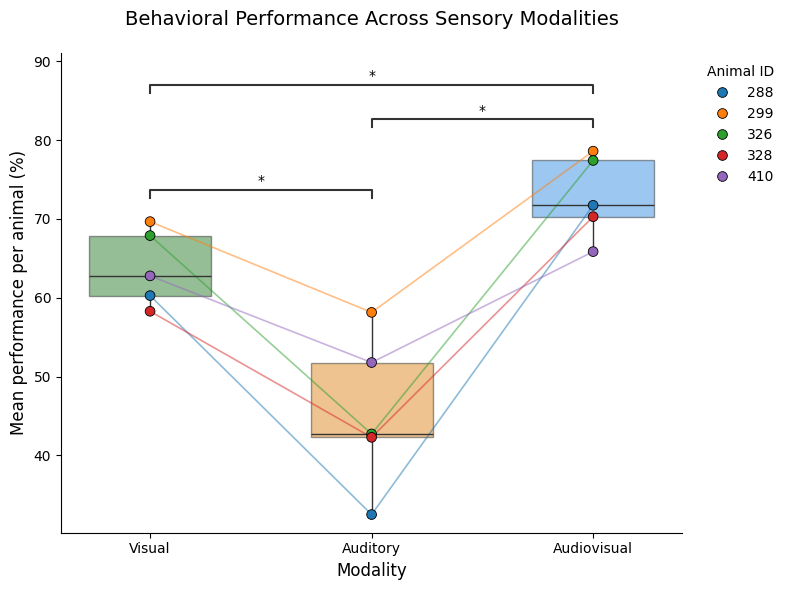

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

from statannotations.Annotator import Annotator

# Prepare data using complete animals only
plot_data = performance_complete.reset_index().melt(
    id_vars="animal_id",
    value_vars=["Visual", "Auditory", "Audiovisual"],
    var_name="modality",
    value_name="performance_pct",
)

order = ["Visual", "Auditory", "Audiovisual"]

box_colors = {
    "Visual": "forestgreen",
    "Auditory": "darkorange",
    "Audiovisual": "dodgerblue",
}

# Assign a unique color to each animal
animal_ids = plot_data["animal_id"].unique()

animal_colors = dict(
    zip(
        animal_ids,
        sns.color_palette("tab10", n_colors=len(animal_ids)),
    )
)

# Create figure
fig, ax = plt.subplots(figsize=(8, 6))

# Boxplot
sns.boxplot(
    data=plot_data,
    x="modality",
    y="performance_pct",
    order=order,
    hue="modality",
    palette=box_colors,
    boxprops=dict(alpha=.5),
    legend=False,
    fliersize=0,
    showcaps=False,
    width=0.55,
    ax=ax,
)

# Connect measurements from the same animal
for animal_id, animal_data in plot_data.groupby("animal_id"):
    animal_data = (
        animal_data
        .set_index("modality")
        .reindex(order)
    )

    ax.plot(
        range(len(order)),
        animal_data["performance_pct"],
        color=animal_colors[animal_id],
        alpha=0.5,
        linewidth=1.2,
        zorder=2,
    )

# Individual animal observations
sns.stripplot(
    data=plot_data,
    x="modality",
    y="performance_pct",
    order=order,
    hue="animal_id",
    palette=animal_colors,
    size=7,
    jitter=0,
    edgecolor="black",
    linewidth=0.6,
    ax=ax,
    zorder=3,
)

# Statistical annotations
pairs = [
    ("Visual", "Auditory"),
    ("Visual", "Audiovisual"),
    ("Auditory", "Audiovisual"),
]

# Use Holm-adjusted p-values calculated from performance_complete
p_values_for_annotations = [
    p_adjusted[2],
    p_adjusted[0],
    p_adjusted[1],
]

annotator = Annotator(
    ax,
    pairs,
    data=plot_data,
    x="modality",
    y="performance_pct",
    order=order,
)

annotator.set_pvalues(p_values_for_annotations)

annotator.configure(
    text_format="star",
    loc="inside",
    verbose=0,
)

annotator.annotate()

# Formatting
ax.set_xlabel("Modality", fontsize=12)
ax.set_ylabel("Mean performance per animal (%)", fontsize=12)

ax.set_title(
    "Behavioral Performance Across Sensory Modalities",
    fontsize=14,
    pad=20,
)

ax.legend(
    title="Animal ID",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

sns.despine()
plt.tight_layout()
plt.show()

## Unimodals Vs Multimodals

In [63]:
# Pivot: one row per animal, one column per modality.
performance_pivot = performance_by_animal.pivot(
    index="animal_id",
    columns="modality",
    values="performance_pct",
)

# Keep animals with complete data.
performance_complete = performance_pivot[
    ["Visual", "Auditory", "Audiovisual"]
].dropna()

# Calculate average unimodal performance per animal.
performance_complete["Unimodal"] = (
    performance_complete["Visual"] +
    performance_complete["Auditory"]
) / 2

# Rename Audiovisual to Multimodal.
performance_complete = performance_complete.rename(
    columns={"Audiovisual": "Multimodal"}
)

performance_complete[
    ["Unimodal", "Multimodal"]
]

modality,Unimodal,Multimodal
animal_id,,
288,46.387987,71.730791
299,63.904318,78.599690
326,55.309760,77.418079
328,50.291578,70.286997
410,57.282198,65.856034


In [64]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

unimodal_vs_multimodal = ttest_rel(
    performance_complete["Multimodal"],
    performance_complete["Unimodal"],
)

print(f"Number of animals: {len(performance_complete)}")
print(
    f"Multimodal vs Unimodal: "
    f"t={unimodal_vs_multimodal.statistic:.3f}, "
    f"p={unimodal_vs_multimodal.pvalue:.4f}"
)

Number of animals: 5
Multimodal vs Unimodal: t=6.143, p=0.0036


/home/jupyter-anastasios/.local/lib/python3.10/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


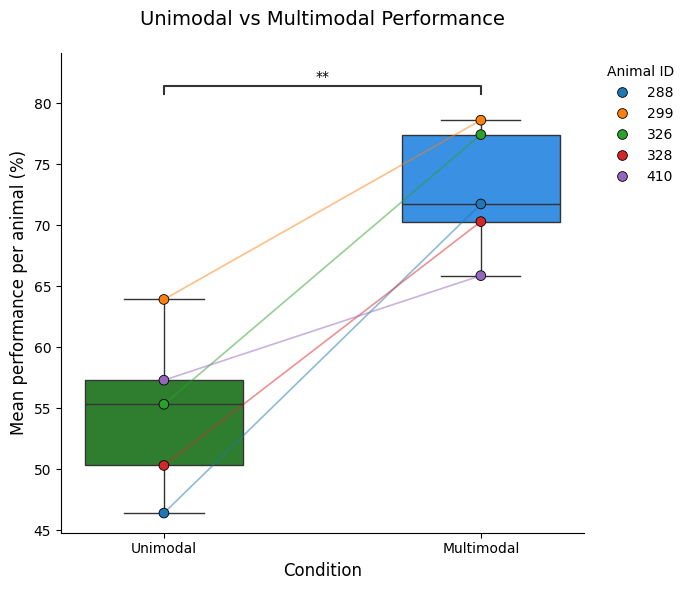

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

from statannotations.Annotator import Annotator

# Prepare plotting data
plot_data = performance_complete[
    ["Unimodal", "Multimodal"]
].reset_index().melt(
    id_vars="animal_id",
    var_name="condition",
    value_name="performance_pct",
)

order = ["Unimodal", "Multimodal"]

box_colors = {
    "Unimodal": "forestgreen",
    "Multimodal": "dodgerblue",
}

# Individual animal colors
animal_ids = plot_data["animal_id"].unique()

animal_colors = dict(
    zip(
        animal_ids,
        sns.color_palette("tab10", n_colors=len(animal_ids)),
    )
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

# Boxplot
sns.boxplot(
    data=plot_data,
    x="condition",
    y="performance_pct",
    order=order,
    hue="condition",
    palette=box_colors,
    legend=False,
    fliersize=0,
    width=0.5,
    ax=ax,
)

# Connect paired observations
for animal_id, animal_data in plot_data.groupby("animal_id"):
    animal_data = (
        animal_data
        .set_index("condition")
        .reindex(order)
    )

    ax.plot(
        range(len(order)),
        animal_data["performance_pct"],
        color=animal_colors[animal_id],
        alpha=0.5,
        linewidth=1.2,
        zorder=2,
    )

# Individual observations
sns.stripplot(
    data=plot_data,
    x="condition",
    y="performance_pct",
    order=order,
    hue="animal_id",
    palette=animal_colors,
    size=7,
    jitter=0,
    edgecolor="black",
    linewidth=0.6,
    ax=ax,
    zorder=3,
)

# Statistical annotation
pairs = [
    ("Unimodal", "Multimodal"),
]

annotator = Annotator(
    ax,
    pairs,
    data=plot_data,
    x="condition",
    y="performance_pct",
    order=order,
)

annotator.set_pvalues([unimodal_vs_multimodal.pvalue])

annotator.configure(
    text_format="star",
    loc="inside",
    verbose=0,
)

annotator.annotate()

# Formatting
ax.set_xlabel("Condition", fontsize=12)
ax.set_ylabel("Mean performance per animal (%)", fontsize=12)

ax.set_title(
    "Unimodal vs Multimodal Performance",
    fontsize=14,
    pad=20,
)

ax.legend(
    title="Animal ID",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

sns.despine()
plt.tight_layout()
plt.show()